<a href="https://colab.research.google.com/github/Sppgg/geoai-land-cover-classifier/blob/main/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import PIL

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Pillow:", PIL.__version__)


Python: 3.13.16
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
Matplotlib: 3.10.0
Pillow: 11.3.0


In [2]:

from torchvision.datasets import EuroSAT

dataset = EuroSAT(
    root="./data",
    download=True
)

print("Número de imágenes:", len(dataset))
print("Categorías:", dataset.classes)

imagen, etiqueta = dataset[0]

print("Tamaño de la imagen:", imagen.size)
print("Primera categoría:", dataset.classes[etiqueta])


100%|██████████| 94.3M/94.3M [00:01<00:00, 92.8MB/s]


Número de imágenes: 27000
Categorías: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Tamaño de la imagen: (64, 64)
Primera categoría: AnnualCrop



## 02. Exploración visual del dataset

### Objetivo
Visualizar una imagen representativa de cada una de las
10 categorías de EuroSAT RGB.

### ¿Por qué es importante?
Antes de entrenar un modelo debemos conocer nuestros datos:

- Qué categorías existen.
- Qué diferencias visuales presentan.
- Qué clases podrían confundirse entre sí.
- Qué limitaciones tiene la resolución de 64 × 64 píxeles.

En esta etapa no entrenamos ningún modelo.
Realizamos un análisis exploratorio de datos (EDA).


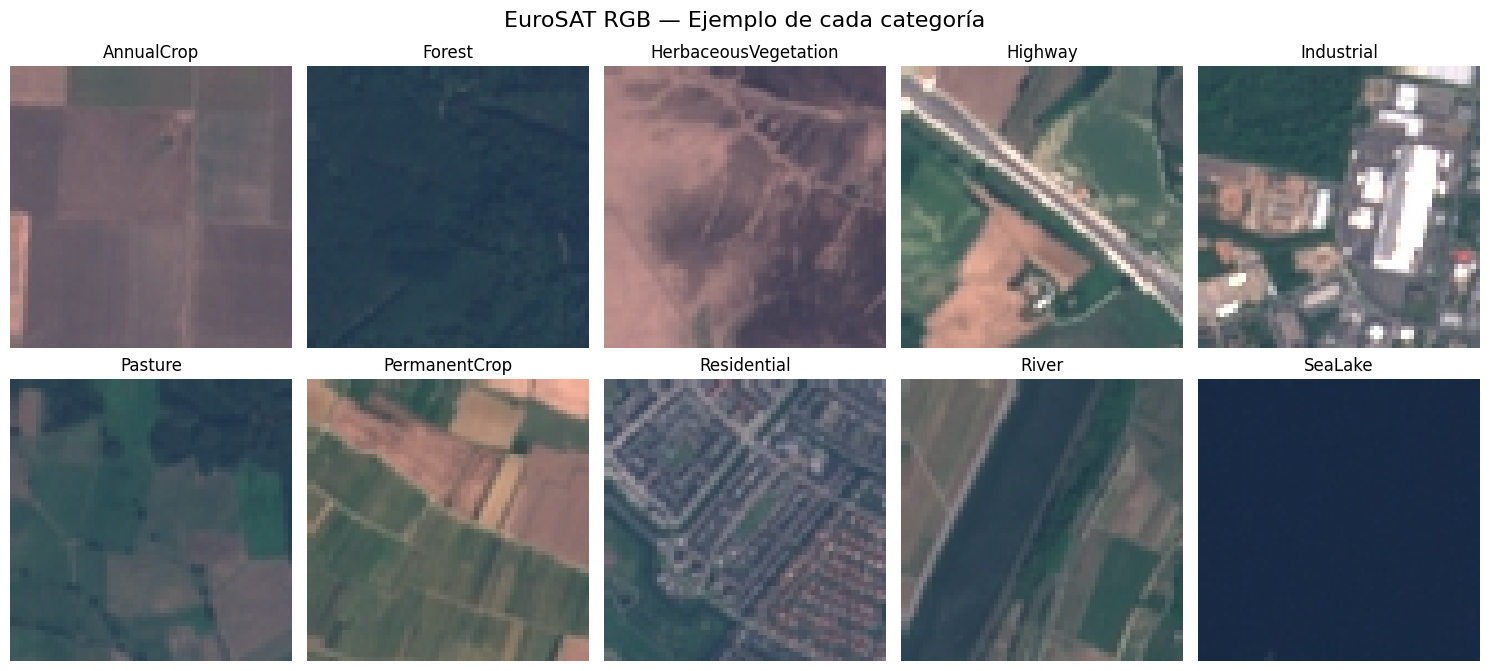

In [3]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 02: Exploración visual de EuroSAT
# ============================================================

# Importamos pyplot para crear visualizaciones.
# Utilizamos el alias habitual "plt".
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Preparar la figura
# ------------------------------------------------------------

# Creamos una cuadrícula de 2 filas y 5 columnas.
# Así podremos mostrar las 10 categorías de EuroSAT.
figura, ejes = plt.subplots(
    nrows=2,
    ncols=5,
    figsize=(15, 7)
)

# Convertimos la matriz de ejes en una lista plana.
# Esto facilita recorrer todas las posiciones con un bucle.
ejes = ejes.flatten()

# ------------------------------------------------------------
# 2. Seleccionar una imagen de cada categoría
# ------------------------------------------------------------

# dataset.classes contiene los nombres de las 10 clases.
# dataset.samples contiene pares:
# (ruta_de_imagen, etiqueta_numerica)
#
# Seleccionamos la primera imagen encontrada de cada clase.
# Son ejemplos, no una muestra aleatoria ni representativa
# de toda la variabilidad del dataset.

for indice_clase, nombre_clase in enumerate(dataset.classes):

    # Buscamos el índice de la primera imagen cuya etiqueta
    # coincida con la clase que estamos recorriendo.
    indice_imagen = next(
        indice
        for indice, (_, etiqueta) in enumerate(dataset.samples)
        if etiqueta == indice_clase
    )

    # Recuperamos la imagen y su etiqueta.
    # La imagen es un objeto PIL.Image.
    imagen, etiqueta = dataset[indice_imagen]

    # Mostramos la imagen en su posición correspondiente.
    ejes[indice_clase].imshow(imagen)

    # Colocamos el nombre de la categoría como título.
    ejes[indice_clase].set_title(nombre_clase)

    # Ocultamos los ejes numéricos porque no aportan
    # información relevante a esta visualización.
    ejes[indice_clase].axis("off")

# ------------------------------------------------------------
# 3. Presentar el resultado
# ------------------------------------------------------------

# Añadimos un título general.
figura.suptitle(
    "EuroSAT RGB — Ejemplo de cada categoría",
    fontsize=16
)

# Ajustamos los espacios para evitar superposiciones.
plt.tight_layout()

# Mostramos la figura.
plt.show()



## 03. Distribución de categorías

### Objetivo
Analizar cuántas imágenes pertenecen a cada una de las
10 categorías de EuroSAT.

### Conceptos
- **Clase:** categoría que queremos predecir.
- **Etiqueta:** valor numérico que identifica una clase.
- **Distribución de clases:** cantidad de ejemplos por categoría.
- **Desbalance de clases:** situación en la que algunas clases
  tienen muchos más ejemplos que otras.

### ¿Por qué importa?
La distribución de las clases influye en el entrenamiento
y en la interpretación de las métricas del modelo.


,Categoría,Imágenes,Porcentaje
0,AnnualCrop,3000,11.11
1,Forest,3000,11.11
2,HerbaceousVegetation,3000,11.11
7,Residential,3000,11.11
9,SeaLake,3000,11.11
3,Highway,2500,9.26
6,PermanentCrop,2500,9.26
4,Industrial,2500,9.26
8,River,2500,9.26
5,Pasture,2000,7.41


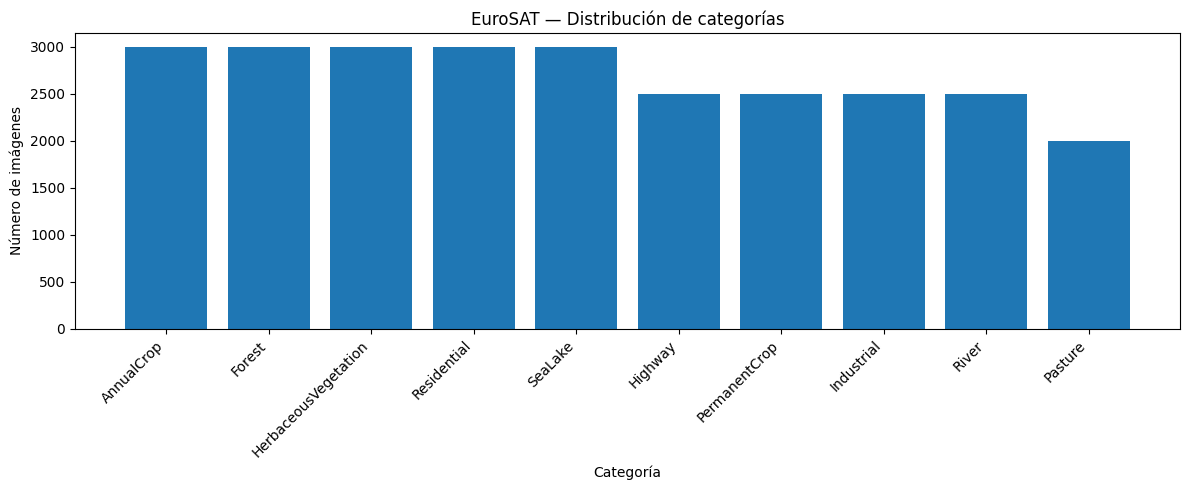

Total de imágenes: 27000
Número de categorías: 10


In [4]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 03: Distribución de categorías
# ============================================================

# Importamos Counter para contar cuántas veces
# aparece cada etiqueta en el dataset.
from collections import Counter

# Importamos pandas para crear una tabla.
import pandas as pd

# Importamos matplotlib para visualizar los resultados.
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Obtener las etiquetas
# ------------------------------------------------------------

# dataset.targets contiene la etiqueta numérica
# correspondiente a cada imagen.
#
# Por ejemplo:
# 0 = AnnualCrop
# 1 = Forest
# etc.
etiquetas = dataset.targets

# Contamos cuántas imágenes hay de cada categoría.
conteo = Counter(etiquetas)

# ------------------------------------------------------------
# 2. Crear una tabla de resultados
# ------------------------------------------------------------

# Construimos una lista de diccionarios.
# Cada diccionario representa una fila de la tabla.
filas = []

for indice_clase, nombre_clase in enumerate(dataset.classes):

    # Cantidad de imágenes de esta categoría.
    cantidad = conteo[indice_clase]

    # Porcentaje respecto al total del dataset.
    porcentaje = (cantidad / len(dataset)) * 100

    filas.append({
        "Categoría": nombre_clase,
        "Imágenes": cantidad,
        "Porcentaje": round(porcentaje, 2)
    })

# Convertimos la lista en un DataFrame de pandas.
distribucion = pd.DataFrame(filas)

# Mostramos la tabla ordenada de mayor a menor cantidad.
distribucion = distribucion.sort_values(
    by="Imágenes",
    ascending=False
)

display(distribucion)

# ------------------------------------------------------------
# 3. Representar las cantidades gráficamente
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.bar(
    distribucion["Categoría"],
    distribucion["Imágenes"]
)

plt.title("EuroSAT — Distribución de categorías")
plt.xlabel("Categoría")
plt.ylabel("Número de imágenes")

# Rotamos las etiquetas para facilitar su lectura.
plt.xticks(rotation=45, ha="right")

# Ajustamos los márgenes.
plt.tight_layout()

# Mostramos el gráfico.
plt.show()

# ------------------------------------------------------------
# 4. Comprobar el total
# ------------------------------------------------------------

print("Total de imágenes:", distribucion["Imágenes"].sum())
print("Número de categorías:", len(distribucion))



## 04. División del dataset

### Objetivo
Separar EuroSAT en tres conjuntos independientes:

- Entrenamiento: 70 %
- Validación: 15 %
- Prueba: 15 %

### Conceptos importantes

**Train:** datos utilizados para ajustar el modelo.

**Validation:** datos utilizados para comparar modelos,
seleccionar hiperparámetros y tomar decisiones.

**Test:** datos reservados para medir el rendimiento final.

**Estratificación:** técnica que mantiene aproximadamente
la misma distribución de clases en cada conjunto.

**Data leakage:** ocurre cuando información que debería
estar reservada para la evaluación influye en el entrenamiento
o en la selección del modelo.

### Precaución geoespacial

Esta división se realiza por imagen y etiqueta, no por
ubicación geográfica.

Si existen imágenes próximas o espacialmente relacionadas,
los resultados podrían sobreestimar la capacidad de
generalización a regiones completamente nuevas.

Por tanto, interpretaremos las métricas como resultados
sobre una división aleatoria de EuroSAT, no como evidencia
de generalización geográfica independiente.


In [5]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 04: División estratificada del dataset
# ============================================================

# train_test_split divide una colección de datos en
# subconjuntos aleatorios, de forma reproducible.
from sklearn.model_selection import train_test_split

# NumPy nos permite trabajar con arrays numéricos.
import numpy as np

# ------------------------------------------------------------
# 1. Preparar índices y etiquetas
# ------------------------------------------------------------

# Cada índice identifica una imagen del dataset.
# Por ejemplo, el índice 0 corresponde a dataset[0].
#
# No cargamos todas las imágenes en memoria:
# trabajamos únicamente con sus posiciones.
indices = np.arange(len(dataset))

# Convertimos las etiquetas a un array de NumPy.
etiquetas = np.array(dataset.targets)

# ------------------------------------------------------------
# 2. Primera división: Train (70 %) y temporal (30 %)
# ------------------------------------------------------------

# test_size=0.30 reserva el 30 % para dividirlo después
# entre validación y prueba.
#
# random_state=42 fija la semilla aleatoria y permite
# reproducir exactamente esta división.
#
# stratify=etiquetas conserva las proporciones de clases.
indices_train, indices_temporales = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=etiquetas
)

# ------------------------------------------------------------
# 3. Segunda división: Validation (15 %) y Test (15 %)
# ------------------------------------------------------------

# Obtenemos las etiquetas de las imágenes temporales.
etiquetas_temporales = etiquetas[indices_temporales]

# Dividimos el 30 % reservado en dos mitades iguales.
#
# El 50 % del 30 % original equivale al 15 % del total.
indices_val, indices_test = train_test_split(
    indices_temporales,
    test_size=0.50,
    random_state=42,
    stratify=etiquetas_temporales
)

# ------------------------------------------------------------
# 4. Mostrar los tamaños
# ------------------------------------------------------------

print("Entrenamiento:", len(indices_train))
print("Validación:", len(indices_val))
print("Prueba:", len(indices_test))

# Verificamos que no falte ninguna imagen.
assert (
    len(indices_train)
    + len(indices_val)
    + len(indices_test)
    == len(dataset)
), "Error: el número de imágenes no coincide."

# Comprobamos que ningún índice esté repetido
# entre los tres conjuntos.
assert len(
    set(indices_train)
    | set(indices_val)
    | set(indices_test)
) == len(dataset), "Error: hay índices duplicados."

print("División completada correctamente.")


Entrenamiento: 18900
Validación: 4050
Prueba: 4050
División completada correctamente.



## 05. Verificación de la estratificación

### Objetivo

Comprobar que entrenamiento, validación y prueba
conservan aproximadamente la distribución original
de las diez clases de EuroSAT.

### Conceptos

- **Estratificación:** reparto de los datos manteniendo
  aproximadamente la proporción de cada clase.

- **Distribución relativa:** porcentaje de imágenes
  que pertenece a cada categoría.

- **Validación del split:** comprobación de que los
  conjuntos se han construido como esperamos.

### ¿Qué esperamos?

Que la proporción de cada categoría sea muy similar
en los tres conjuntos.

Esta comprobación no garantiza independencia
geográfica entre imágenes.


,Categoría,Train (%),Validation (%),Test (%)
0,AnnualCrop,11.11,11.11,11.11
1,Forest,11.11,11.11,11.11
2,HerbaceousVegetation,11.11,11.11,11.11
3,Highway,9.26,9.26,9.26
4,Industrial,9.26,9.26,9.26
5,Pasture,7.41,7.41,7.41
6,PermanentCrop,9.26,9.26,9.26
7,Residential,11.11,11.11,11.11
8,River,9.26,9.26,9.26
9,SeaLake,11.11,11.11,11.11


Diferencia máxima entre conjuntos: 0.0 puntos porcentuales


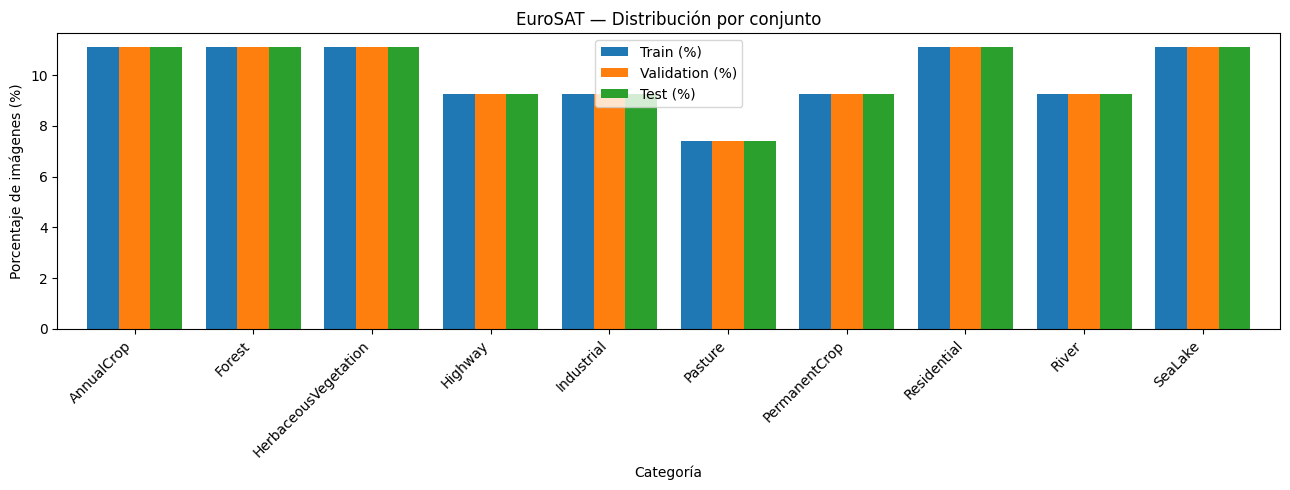

In [6]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 05: Verificación de la estratificación
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Crear una función para calcular proporciones
# ------------------------------------------------------------

def calcular_distribucion(indices_conjunto):
    """
    Calcula el porcentaje de imágenes de cada clase.

    Parámetros
    ----------
    indices_conjunto:
        Índices de las imágenes que pertenecen al conjunto.

    Devuelve
    --------
    Un array con los porcentajes de las 10 categorías,
    en el mismo orden que dataset.classes.
    """

    # Recuperamos las etiquetas correspondientes
    # a las imágenes de este conjunto.
    etiquetas_conjunto = etiquetas[indices_conjunto]

    # Contamos cuántas imágenes hay de cada clase.
    # minlength garantiza que el resultado incluya
    # las 10 categorías, incluso si alguna tuviera 0.
    conteos = np.bincount(
        etiquetas_conjunto,
        minlength=len(dataset.classes)
    )

    # Convertimos los recuentos a porcentajes.
    porcentajes = conteos / len(indices_conjunto) * 100

    return porcentajes


# ------------------------------------------------------------
# 2. Calcular la distribución de cada conjunto
# ------------------------------------------------------------

distribucion_train = calcular_distribucion(indices_train)
distribucion_val = calcular_distribucion(indices_val)
distribucion_test = calcular_distribucion(indices_test)

# ------------------------------------------------------------
# 3. Crear una tabla comparativa
# ------------------------------------------------------------

tabla_estratificacion = pd.DataFrame({
    "Categoría": dataset.classes,
    "Train (%)": distribucion_train,
    "Validation (%)": distribucion_val,
    "Test (%)": distribucion_test
})

# Redondeamos únicamente para mostrar los resultados.
# Los arrays originales conservan su precisión.
display(tabla_estratificacion.round(2))

# ------------------------------------------------------------
# 4. Medir la diferencia máxima entre conjuntos
# ------------------------------------------------------------

# Calculamos, por cada categoría, la diferencia entre
# el porcentaje más alto y el más bajo.
columnas_porcentajes = [
    "Train (%)",
    "Validation (%)",
    "Test (%)"
]

diferencias = (
    tabla_estratificacion[columnas_porcentajes].max(axis=1)
    - tabla_estratificacion[columnas_porcentajes].min(axis=1)
)

print(
    "Diferencia máxima entre conjuntos:",
    round(diferencias.max(), 3),
    "puntos porcentuales"
)

# ------------------------------------------------------------
# 5. Visualizar los porcentajes
# ------------------------------------------------------------

# Cada categoría tendrá tres barras:
# una de entrenamiento, otra de validación y otra de prueba.
eje = tabla_estratificacion.set_index("Categoría").plot(
    kind="bar",
    figsize=(13, 5),
    width=0.8
)

eje.set_title("EuroSAT — Distribución por conjunto")
eje.set_xlabel("Categoría")
eje.set_ylabel("Porcentaje de imágenes (%)")

# Ajustamos las etiquetas del eje horizontal.
plt.xticks(rotation=45, ha="right")

# Evitamos que los elementos se superpongan.
plt.tight_layout()

# Mostramos el gráfico.
plt.show()



## 06. Preparación de imágenes para Machine Learning

### Objetivo

Convertir las imágenes RGB de EuroSAT en vectores numéricos
para utilizarlos como entrada de un modelo de scikit-learn.

### Conceptos

- **Píxel:** unidad mínima de información de una imagen.
- **RGB:** representación mediante tres canales de color:
  rojo, verde y azul.
- **Feature:** característica numérica utilizada como
  entrada por un modelo.
- **Flattening:** transformación de una matriz
  multidimensional en un vector unidimensional.
- **Normalización:** transformación de los valores a
  una escala determinada.

### Decisión técnica

Usaremos inicialmente los valores RGB normalizados
entre 0 y 1.

Esta representación servirá para crear un modelo
de referencia, aunque no aprovecha explícitamente
las relaciones espaciales entre los píxeles.


In [7]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 06: Conversión de imágenes a características
# ============================================================

import numpy as np

# ------------------------------------------------------------
# 1. Seleccionar una imagen del conjunto de entrenamiento
# ------------------------------------------------------------

# Usamos el primer índice de entrenamiento.
# No utilizamos el conjunto de prueba para experimentar.
indice_imagen = indices_train[0]

# Recuperamos la imagen y su etiqueta.
imagen_pil, etiqueta = dataset[indice_imagen]

# ------------------------------------------------------------
# 2. Convertir la imagen a un array numérico
# ------------------------------------------------------------

# Una imagen PIL es un objeto preparado para trabajar
# con imágenes. NumPy permite representar sus píxeles
# como números.
imagen_array = np.array(imagen_pil)

print("Forma original:", imagen_array.shape)
print("Tipo de dato:", imagen_array.dtype)

# ------------------------------------------------------------
# 3. Normalizar los valores RGB
# ------------------------------------------------------------

# Las imágenes RGB de 8 bits utilizan valores entre
# 0 y 255 para representar la intensidad de cada canal.
#
# Convertimos los valores a float32 y dividimos entre
# 255 para obtener valores entre 0 y 1.
imagen_normalizada = imagen_array.astype(np.float32) / 255.0

print("Valor mínimo:", imagen_normalizada.min())
print("Valor máximo:", imagen_normalizada.max())

# ------------------------------------------------------------
# 4. Convertir la imagen en un vector
# ------------------------------------------------------------

# flatten() transforma una matriz de dimensiones
# (64, 64, 3) en un vector de 12.288 elementos.
#
# Se conserva la información numérica, pero se pierde
# la organización espacial explícita de la matriz.
vector_caracteristicas = imagen_normalizada.flatten()

print("Forma del vector:", vector_caracteristicas.shape)
print("Número de características:", vector_caracteristicas.size)

# ------------------------------------------------------------
# 5. Mostrar la categoría correspondiente
# ------------------------------------------------------------

print("Categoría:", dataset.classes[etiqueta])


Forma original: (64, 64, 3)
Tipo de dato: uint8
Valor mínimo: 0.21960784
Valor máximo: 0.76862746
Forma del vector: (12288,)
Número de características: 12288
Categoría: Residential



## 07. Preparación de una muestra para el primer modelo

### Objetivo

Preparar 2.000 imágenes de entrenamiento para construir
un primer modelo de clasificación.

### ¿Por qué utilizamos una muestra?

El dataset de entrenamiento contiene 18.900 imágenes.

Para desarrollar y comprobar nuestro primer pipeline,
empezaremos con una muestra más pequeña.

Esto permite:

- Reducir el consumo de memoria.
- Acelerar los experimentos iniciales.
- Identificar errores antes de procesar todo el dataset.
- Comparar modelos de forma más eficiente.

### Decisiones técnicas

1. Seleccionaremos exclusivamente imágenes del conjunto
   de entrenamiento.

2. Utilizaremos muestreo estratificado para conservar
   aproximadamente las proporciones de clases.

3. Normalizaremos los valores RGB entre 0 y 1.

4. Convertiremos cada imagen en un vector de 12.288
   características.

5. Guardaremos las características en una matriz X y
   las etiquetas en un vector y.

El conjunto de validación y el de prueba permanecerán
separados.

### Convenciones de Machine Learning

- X: variables de entrada o características.
- y: variable objetivo o etiqueta que queremos predecir.
- X_train: características de entrenamiento.
- y_train: etiquetas de entrenamiento.


In [8]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 07: Preparación de una muestra de entrenamiento
# ============================================================

import numpy as np
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. Seleccionar 2.000 imágenes de entrenamiento
# ------------------------------------------------------------

# Partimos exclusivamente de indices_train.
# De esta forma no incorporamos imágenes de validación
# ni de prueba durante el entrenamiento.
#
# train_size=2000 selecciona exactamente 2.000 imágenes.
#
# random_state=42 permite reproducir la selección.
#
# stratify mantiene aproximadamente las proporciones
# originales de las diez categorías.

indices_muestra, _ = train_test_split(
    indices_train,
    train_size=2000,
    random_state=42,
    stratify=etiquetas[indices_train]
)

print("Imágenes seleccionadas:", len(indices_muestra))

# ------------------------------------------------------------
# 2. Crear una función de preparación de imágenes
# ------------------------------------------------------------

def preparar_imagen(indice):
    """
    Convierte una imagen de EuroSAT en un vector numérico.

    Parámetros
    ----------
    indice : int
        Posición de la imagen dentro del dataset.

    Devuelve
    --------
    vector : np.ndarray
        Vector de 12.288 características normalizadas.

    etiqueta : int
        Identificador numérico de la categoría.
    """

    # Recuperamos una imagen RGB y su etiqueta.
    imagen, etiqueta = dataset[int(indice)]

    # Convertimos la imagen a un array de NumPy.
    imagen_array = np.asarray(imagen)

    # Normalizamos los valores RGB a [0, 1].
    # float32 reduce el consumo de memoria frente a float64.
    imagen_normalizada = (
        imagen_array.astype(np.float32) / 255.0
    )

    # Convertimos la matriz (64, 64, 3)
    # en un vector de 12.288 características.
    vector = imagen_normalizada.flatten()

    return vector, etiqueta


# ------------------------------------------------------------
# 3. Procesar todas las imágenes de la muestra
# ------------------------------------------------------------

# Creamos dos listas:
# una para los vectores y otra para las etiquetas.
caracteristicas = []
etiquetas_muestra = []

for indice in indices_muestra:

    vector, etiqueta = preparar_imagen(indice)

    caracteristicas.append(vector)
    etiquetas_muestra.append(etiqueta)

# ------------------------------------------------------------
# 4. Convertir las listas en arrays
# ------------------------------------------------------------

# Cada fila de X representa una imagen.
# Cada columna representa una característica RGB.
X_train_sample = np.stack(caracteristicas)

# y contiene las etiquetas numéricas correspondientes.
y_train_sample = np.array(etiquetas_muestra)

# ------------------------------------------------------------
# 5. Comprobar las dimensiones
# ------------------------------------------------------------

print("Forma de X:", X_train_sample.shape)
print("Forma de y:", y_train_sample.shape)

print("Tipo de dato X:", X_train_sample.dtype)

print("Valor mínimo:", X_train_sample.min())
print("Valor máximo:", X_train_sample.max())

# Verificamos que haya una etiqueta por imagen.
assert len(X_train_sample) == len(y_train_sample)

# Verificamos que las imágenes tengan 12.288 características.
assert X_train_sample.shape[1] == 64 * 64 * 3

print("Muestra preparada correctamente.")


Imágenes seleccionadas: 2000
Forma de X: (2000, 12288)
Forma de y: (2000,)
Tipo de dato X: float32
Valor mínimo: 0.06666667
Valor máximo: 1.0
Muestra preparada correctamente.



## 08. Primer modelo: clasificación logística con SGD

### Objetivo

Entrenar nuestro primer clasificador de imágenes
satelitales usando 2.000 imágenes de EuroSAT RGB.

### Conceptos importantes

**Modelo:** algoritmo que aprende relaciones entre las
características de entrada (X) y las etiquetas (y).

**Entrenamiento:** proceso de ajustar los parámetros
del modelo utilizando ejemplos etiquetados.

**Clasificador lineal:** modelo que combina las
características mediante pesos para producir predicciones.

**Descenso de gradiente estocástico (SGD):**
método de optimización que actualiza los parámetros
a partir de ejemplos de entrenamiento.

**Baseline:** primer modelo de referencia contra el que
compararemos técnicas posteriores.

### Decisión técnica

Utilizamos SGDClassifier con pérdida logística porque:

- Es adecuado para experimentar con muchas características.
- Permite entrenar modelos lineales de forma eficiente.
- Proporciona una referencia sencilla.
- Nos permite estudiar el funcionamiento del entrenamiento
  antes de introducir modelos más complejos.

### Limitaciones

El modelo recibe píxeles RGB aplanados y no utiliza
explícitamente la estructura espacial de la imagen.

No esperamos necesariamente un rendimiento alto.
El objetivo inicial es establecer una referencia medible.


In [9]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 08: Entrenamiento del primer modelo (baseline)
# ============================================================

import time

# SGDClassifier permite entrenar clasificadores lineales
# mediante descenso de gradiente estocástico.
from sklearn.linear_model import SGDClassifier

# accuracy_score mide el porcentaje de predicciones
# correctas sobre el total de ejemplos evaluados.
from sklearn.metrics import accuracy_score

# ------------------------------------------------------------
# 1. Definir nuestro primer modelo
# ------------------------------------------------------------

modelo_baseline = SGDClassifier(
    loss="log_loss",      # Utiliza una función de pérdida logística.
    max_iter=1000,       # Número máximo de épocas de entrenamiento.
    tol=1e-3,            # Criterio de parada por mejora insuficiente.
    random_state=42,     # Permite reproducir la aleatoriedad.
    n_jobs=-1            # Utiliza los núcleos disponibles cuando aplica.
)

# ------------------------------------------------------------
# 2. Entrenar el modelo
# ------------------------------------------------------------

# Registramos el instante inicial para medir el tiempo.
inicio = time.time()

# fit() aprende los parámetros del modelo.
#
# X_train_sample: los valores RGB de nuestras imágenes.
# y_train_sample: la clase real de cada imagen.
#
# IMPORTANTE:
# Entrenamos exclusivamente con los datos de entrenamiento.
# No utilizamos validación ni prueba en este paso.
modelo_baseline.fit(
    X_train_sample,
    y_train_sample
)

# Calculamos el tiempo transcurrido.
tiempo_entrenamiento = time.time() - inicio

# ------------------------------------------------------------
# 3. Obtener predicciones sobre entrenamiento
# ------------------------------------------------------------

# predict() utiliza el modelo entrenado para estimar
# la categoría de cada imagen.
predicciones_train = modelo_baseline.predict(
    X_train_sample
)

# ------------------------------------------------------------
# 4. Calcular la accuracy de entrenamiento
# ------------------------------------------------------------

# Comparamos las predicciones con las etiquetas reales.
accuracy_train = accuracy_score(
    y_train_sample,
    predicciones_train
)

# ------------------------------------------------------------
# 5. Mostrar los resultados
# ------------------------------------------------------------

print("Modelo:", type(modelo_baseline).__name__)

print(
    "Tiempo de entrenamiento:",
    round(tiempo_entrenamiento, 2),
    "segundos"
)

print(
    "Accuracy de entrenamiento:",
    round(accuracy_train * 100, 2),
    "%"
)

print(
    "Número de clases aprendidas:",
    len(modelo_baseline.classes_)
)

print("Entrenamiento completado.")


Modelo: SGDClassifier
Tiempo de entrenamiento: 58.79 segundos
Accuracy de entrenamiento: 66.1 %
Número de clases aprendidas: 10
Entrenamiento completado.



## 09. Evaluación inicial del baseline

### Objetivo

Evaluar nuestro primer modelo de clasificación sobre
1.000 imágenes del conjunto de validación.

Estas imágenes no han sido utilizadas durante
el entrenamiento.

### Conceptos

**Generalización:**
Capacidad del modelo para realizar predicciones
sobre ejemplos que no ha visto durante el entrenamiento.

**Accuracy de validación:**
Porcentaje de predicciones correctas en un conjunto
independiente del utilizado para aprender.

**Overfitting (sobreajuste):**
Situación en la que un modelo aprende demasiado
las particularidades del entrenamiento y funciona
peor con datos nuevos.

**Macro-F1:**
Media de los valores F1 de todas las clases,
dando el mismo peso a cada categoría.

### Decisiones técnicas

- Usaremos una muestra estratificada de 1.000 imágenes.
- Mantendremos exactamente el mismo preprocesamiento RGB.
- No volveremos a entrenar el modelo.
- No utilizaremos el conjunto de prueba.
- Compararemos las métricas de entrenamiento y validación.

### Limitación

Esta evaluación utiliza una división aleatoria por
imagen y no garantiza generalización a regiones
geográficas independientes.


In [10]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 09: Evaluación inicial del modelo
# ============================================================

import time
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------------------
# 1. Seleccionar una muestra del conjunto de validación
# ------------------------------------------------------------

# indices_val contiene las 4.050 imágenes reservadas
# anteriormente para validar nuestros modelos.
#
# Elegimos 1.000 de forma estratificada.
# Esto conserva aproximadamente la distribución
# de las diez categorías.
indices_val_muestra, _ = train_test_split(
    indices_val,
    train_size=1000,
    random_state=42,
    stratify=etiquetas[indices_val]
)

# ------------------------------------------------------------
# 2. Preparar las imágenes de validación
# ------------------------------------------------------------

# Reutilizamos preparar_imagen(), la misma función
# utilizada para crear los datos de entrenamiento.
#
# Es fundamental aplicar el mismo preprocesamiento:
# RGB -> float32 -> normalización [0, 1] -> flatten.
#
# No calculamos parámetros estadísticos nuevos
# ni ajustamos el modelo con estos datos.

X_val_lista = []
y_val_lista = []

for indice in indices_val_muestra:

    vector, etiqueta = preparar_imagen(indice)

    X_val_lista.append(vector)
    y_val_lista.append(etiqueta)

# Convertimos las listas en arrays de NumPy.
X_val_sample = np.stack(X_val_lista)
y_val_sample = np.array(y_val_lista)

# ------------------------------------------------------------
# 3. Realizar predicciones
# ------------------------------------------------------------

# predict() utiliza el modelo que ya entrenamos.
# No modificamos sus parámetros.
inicio = time.time()

predicciones_val = modelo_baseline.predict(
    X_val_sample
)

tiempo_inferencia = time.time() - inicio

# ------------------------------------------------------------
# 4. Calcular las métricas
# ------------------------------------------------------------

# Accuracy: proporción total de aciertos.
accuracy_val = accuracy_score(
    y_val_sample,
    predicciones_val
)

# Macro-F1: calcula F1 para cada una de las diez clases
# y obtiene la media sin favorecer las clases mayoritarias.
f1_macro_val = f1_score(
    y_val_sample,
    predicciones_val,
    average="macro",
    zero_division=0
)

# Comparamos las accuracy de entrenamiento y validación.
diferencia_accuracy = accuracy_train - accuracy_val

# ------------------------------------------------------------
# 5. Mostrar los resultados
# ------------------------------------------------------------

print("Modelo:", type(modelo_baseline).__name__)

print("Imágenes de validación:", len(X_val_sample))

print(
    "Accuracy entrenamiento:",
    round(accuracy_train * 100, 2),
    "%"
)

print(
    "Accuracy validación:",
    round(accuracy_val * 100, 2),
    "%"
)

print(
    "Macro-F1 validación:",
    round(f1_macro_val, 4)
)

print(
    "Diferencia de accuracy:",
    round(diferencia_accuracy * 100, 2),
    "puntos porcentuales"
)

print(
    "Tiempo de inferencia:",
    round(tiempo_inferencia, 3),
    "segundos"
)


Modelo: SGDClassifier
Imágenes de validación: 1000
Accuracy entrenamiento: 66.1 %
Accuracy validación: 28.1 %
Macro-F1 validación: 0.2615
Diferencia de accuracy: 38.0 puntos porcentuales
Tiempo de inferencia: 0.027 segundos



## 10. Análisis de errores del modelo baseline

### Objetivo

Identificar qué categorías de EuroSAT clasifica
correctamente el modelo y cuáles confunde.

### Conceptos

**Matriz de confusión:**
Tabla que compara las etiquetas reales con las
predicciones realizadas por el modelo.

- Filas: categorías reales.
- Columnas: categorías predichas.
- Diagonal: predicciones correctas.
- Fuera de la diagonal: errores de clasificación.

**Precision:**
De todas las imágenes predichas como una categoría,
qué proporción pertenece realmente a ella.

**Recall:**
De todas las imágenes reales de una categoría,
qué proporción detecta correctamente el modelo.

**F1-score:**
Media armónica de precision y recall.

### Decisión técnica

Analizaremos el modelo utilizando únicamente la muestra
de validación. El conjunto de prueba permanecerá
reservado para la evaluación final.

No modificaremos el modelo hasta comprender sus errores.


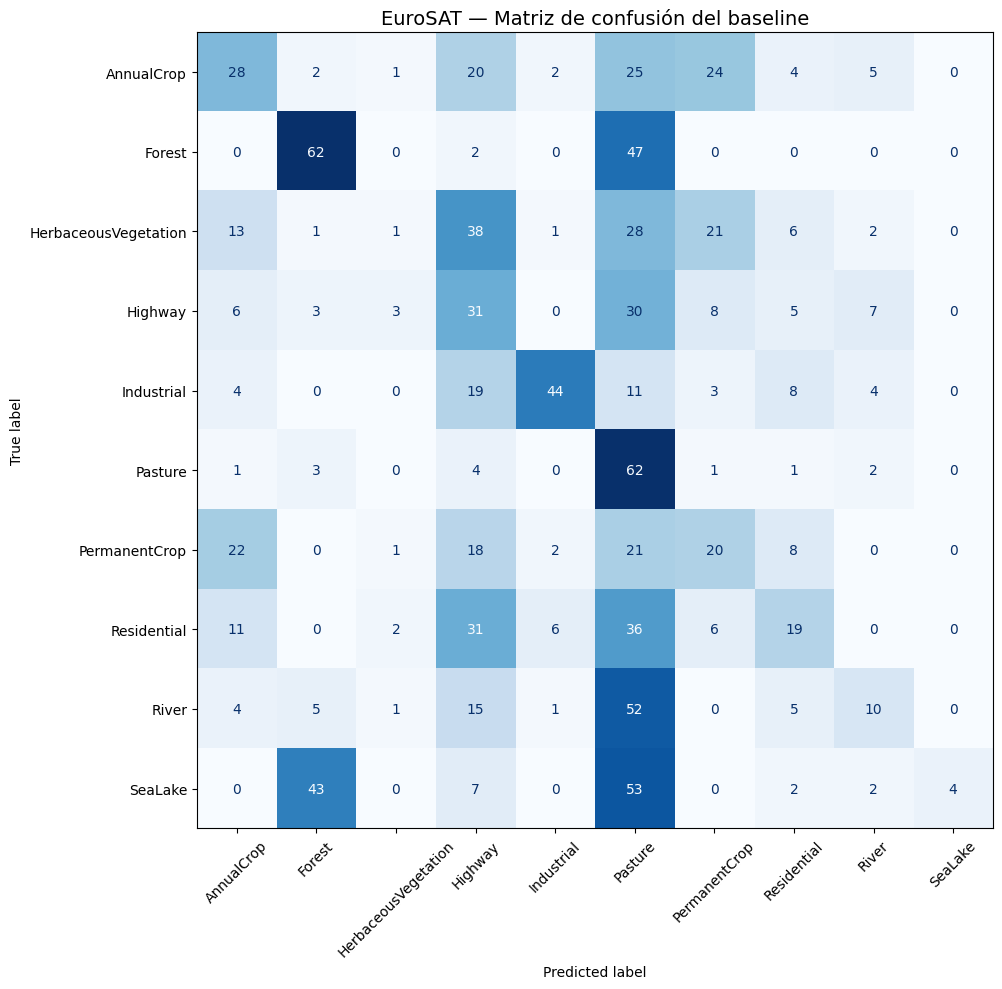

INFORME DE CLASIFICACIÓN
                      precision    recall  f1-score   support

          AnnualCrop       0.31      0.25      0.28       111
              Forest       0.52      0.56      0.54       111
HerbaceousVegetation       0.11      0.01      0.02       111
             Highway       0.17      0.33      0.22        93
          Industrial       0.79      0.47      0.59        93
             Pasture       0.17      0.84      0.28        74
       PermanentCrop       0.24      0.22      0.23        92
         Residential       0.33      0.17      0.22       111
               River       0.31      0.11      0.16        93
             SeaLake       1.00      0.04      0.07       111

            accuracy                           0.28      1000
           macro avg       0.40      0.30      0.26      1000
        weighted avg       0.40      0.28      0.26      1000

Imágenes evaluadas: 1000
Predicciones incorrectas: 719
Predicciones correctas: 281


In [11]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 10: Matriz de confusión y análisis de errores
# ============================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Generar la matriz de confusión
# ------------------------------------------------------------

# Comparamos las categorías reales con las predichas.
#
# Indicamos explícitamente las etiquetas 0 a 9 para
# mantener el orden original de dataset.classes.
matriz_confusion = confusion_matrix(
    y_val_sample,
    predicciones_val,
    labels=range(len(dataset.classes))
)

# ------------------------------------------------------------
# 2. Visualizar la matriz
# ------------------------------------------------------------

figura, eje = plt.subplots(figsize=(12, 10))

# Mostramos los recuentos de imágenes.
# Una celda [i, j] indica cuántas imágenes reales
# de la clase i fueron clasificadas como clase j.
visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion,
    display_labels=dataset.classes
)

visualizacion.plot(
    ax=eje,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

eje.set_title(
    "EuroSAT — Matriz de confusión del baseline",
    fontsize=14
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Informe de clasificación
# ------------------------------------------------------------

# Este informe muestra precision, recall y F1-score
# de cada una de las diez clases.
#
# zero_division=0 evita errores cuando una clase no
# recibe ninguna predicción.
informe = classification_report(
    y_val_sample,
    predicciones_val,
    labels=range(len(dataset.classes)),
    target_names=dataset.classes,
    zero_division=0
)

print("INFORME DE CLASIFICACIÓN")
print(informe)

# ------------------------------------------------------------
# 4. Contar cuántos errores hemos cometido
# ------------------------------------------------------------

errores = (y_val_sample != predicciones_val).sum()

print("Imágenes evaluadas:", len(y_val_sample))
print("Predicciones incorrectas:", errores)
print("Predicciones correctas:", len(y_val_sample) - errores)



## 11. Experimento de mejora: escalado y regularización

### Problema detectado

El primer modelo presenta:

- Accuracy entrenamiento: 66,1 %
- Accuracy validación: 28,1 %
- Macro-F1 validación: 0,2615

También muestra diferencias importantes entre categorías.

### Hipótesis

El escalado de características y la regularización
podrían mejorar la estabilidad y generalización
del clasificador lineal.

### Experimento

Entrenaremos modelos SGDClassifier con distintos
valores de alpha, utilizando StandardScaler.

### Conceptos

**StandardScaler:**
Transforma las características para que tengan
aproximadamente media 0 y desviación estándar 1
en el conjunto de entrenamiento.

**Regularización:**
Técnica que penaliza modelos excesivamente complejos,
reduciendo el riesgo de sobreajuste.

**Pipeline:**
Estructura que encadena transformaciones y modelos.

### Prevención de data leakage

El escalador se ajustará exclusivamente utilizando
los datos de entrenamiento.

En validación se aplicará la transformación aprendida,
sin recalcular medias ni desviaciones.


In [12]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 11: Experimento de escalado y regularización
# ============================================================

import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------------------
# 1. Definir los valores de regularización
# ------------------------------------------------------------

# Probaremos tres valores de alpha.
#
# Un alpha mayor implica regularización más intensa.
# El mejor valor se determinará mediante validación.
valores_alpha = [0.0001, 0.001, 0.01]

# Lista donde almacenaremos los resultados.
resultados = []

# ------------------------------------------------------------
# 2. Entrenar y evaluar cada configuración
# ------------------------------------------------------------

for alpha in valores_alpha:

    print(f"Entrenando modelo con alpha={alpha}...")

    # Creamos un pipeline con dos pasos:
    #
    # 1. StandardScaler: aprende media y desviación
    #    estándar exclusivamente a partir del train.
    #
    # 2. SGDClassifier: entrena un clasificador lineal.
    #
    # Pipeline garantiza que el mismo escalado
    # se aplique durante entrenamiento y predicción.
    modelo = Pipeline([
        (
            "escalador",
            StandardScaler()
        ),
        (
            "clasificador",
            SGDClassifier(
                loss="log_loss",
                alpha=alpha,
                max_iter=1000,
                tol=1e-3,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    # Entrenamos exclusivamente con las 2.000
    # imágenes seleccionadas anteriormente.
    modelo.fit(
        X_train_sample,
        y_train_sample
    )

    # Obtenemos predicciones en validación.
    predicciones = modelo.predict(X_val_sample)

    # Calculamos accuracy.
    accuracy = accuracy_score(
        y_val_sample,
        predicciones
    )

    # Calculamos macro-F1 para dar igual peso
    # a las diez categorías.
    macro_f1 = f1_score(
        y_val_sample,
        predicciones,
        average="macro",
        zero_division=0
    )

    # Guardamos los resultados.
    resultados.append({
        "alpha": alpha,
        "accuracy": accuracy,
        "macro_f1": macro_f1
    })

    print(
        f"Accuracy: {accuracy:.4f} | "
        f"Macro-F1: {macro_f1:.4f}"
    )

# ------------------------------------------------------------
# 3. Comparar las configuraciones
# ------------------------------------------------------------

tabla_resultados = pd.DataFrame(resultados)

# Ordenamos por macro-F1, que será nuestra
# métrica principal de selección.
tabla_resultados = tabla_resultados.sort_values(
    by="macro_f1",
    ascending=False
)

display(tabla_resultados)

# ------------------------------------------------------------
# 4. Identificar la mejor configuración
# ------------------------------------------------------------

mejor_resultado = tabla_resultados.iloc[0]

print(
    "Mejor alpha:",
    mejor_resultado["alpha"]
)

print(
    "Mejor Macro-F1:",
    round(mejor_resultado["macro_f1"], 4)
)


Entrenando modelo con alpha=0.0001...
Accuracy: 0.3580 | Macro-F1: 0.3153
Entrenando modelo con alpha=0.001...
Accuracy: 0.4100 | Macro-F1: 0.3921
Entrenando modelo con alpha=0.01...
Accuracy: 0.4020 | Macro-F1: 0.3757


,alpha,accuracy,macro_f1
1,0.0010,0.410,0.392116
2,0.0100,0.402,0.375711
0,0.0001,0.358,0.315296


Mejor alpha: 0.001
Mejor Macro-F1: 0.3921



## 12. Evaluación de generalización del modelo mejorado

### Objetivo

Comparar el rendimiento en entrenamiento y validación
del modelo seleccionado mediante macro-F1.

### Resultados anteriores

Baseline:
- Accuracy entrenamiento: 66,1 %
- Accuracy validación: 28,1 %
- Macro-F1 validación: 0,2615

Mejor configuración del experimento:
- StandardScaler + SGDClassifier
- alpha = 0.001
- Accuracy validación: 41,0 %
- Macro-F1 validación: 0,3921

### Conceptos

**Generalización:** capacidad del modelo para predecir
correctamente datos no utilizados durante el entrenamiento.

**Brecha de generalización:** diferencia entre el
rendimiento en entrenamiento y validación.

**Regularización:** mecanismo que penaliza determinados
valores de los parámetros del modelo para limitar
su complejidad.

### Precaución

Una brecha pequeña no demuestra por sí sola que el
modelo sea bueno. Un modelo que obtiene resultados
bajos en ambos conjuntos también puede estar
infraajustado (underfitting).


In [13]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 12: Evaluación de generalización
# ============================================================

from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------------------
# 1. Recuperar la configuración seleccionada
# ------------------------------------------------------------

# En el experimento anterior elegimos alpha=0.001
# porque obtuvo el mayor macro-F1 en validación.
#
# Reconstruimos exactamente ese pipeline.
# No cambiamos parámetros ni muestras de datos.

modelo_mejorado = Pipeline([
    (
        "escalador",
        StandardScaler()
    ),
    (
        "clasificador",
        SGDClassifier(
            loss="log_loss",
            alpha=0.001,
            max_iter=1000,
            tol=1e-3,
            random_state=42,
            n_jobs=-1
        )
    )
])

# ------------------------------------------------------------
# 2. Entrenar sobre la misma muestra de 2.000 imágenes
# ------------------------------------------------------------

# fit() ajusta tanto el escalador como el clasificador
# utilizando exclusivamente los datos de entrenamiento.
modelo_mejorado.fit(
    X_train_sample,
    y_train_sample
)

# ------------------------------------------------------------
# 3. Predecir entrenamiento y validación
# ------------------------------------------------------------

pred_train_mejorado = modelo_mejorado.predict(
    X_train_sample
)

pred_val_mejorado = modelo_mejorado.predict(
    X_val_sample
)

# ------------------------------------------------------------
# 4. Calcular métricas comparables
# ------------------------------------------------------------

accuracy_train_mejorado = accuracy_score(
    y_train_sample,
    pred_train_mejorado
)

accuracy_val_mejorado = accuracy_score(
    y_val_sample,
    pred_val_mejorado
)

f1_train_mejorado = f1_score(
    y_train_sample,
    pred_train_mejorado,
    average="macro",
    zero_division=0
)

f1_val_mejorado = f1_score(
    y_val_sample,
    pred_val_mejorado,
    average="macro",
    zero_division=0
)

# ------------------------------------------------------------
# 5. Calcular las diferencias
# ------------------------------------------------------------

brecha_accuracy = (
    accuracy_train_mejorado - accuracy_val_mejorado
)

brecha_f1 = (
    f1_train_mejorado - f1_val_mejorado
)

# ------------------------------------------------------------
# 6. Mostrar resultados
# ------------------------------------------------------------

print("MODELO MEJORADO — GENERALIZACIÓN")
print("-" * 42)

print(f"Accuracy entrenamiento: {accuracy_train_mejorado:.2%}")
print(f"Accuracy validación:    {accuracy_val_mejorado:.2%}")
print(f"Brecha accuracy:        {brecha_accuracy:.2%}")

print()

print(f"Macro-F1 entrenamiento: {f1_train_mejorado:.4f}")
print(f"Macro-F1 validación:    {f1_val_mejorado:.4f}")
print(f"Brecha macro-F1:        {brecha_f1:.4f}")


MODELO MEJORADO — GENERALIZACIÓN
------------------------------------------
Accuracy entrenamiento: 75.70%
Accuracy validación:    41.00%
Brecha accuracy:        34.70%

Macro-F1 entrenamiento: 0.7559
Macro-F1 validación:    0.3921
Brecha macro-F1:        0.3638



## 13. Experimento con características HOG

### Objetivo

Explorar una representación alternativa de las imágenes
mediante Histogram of Oriented Gradients (HOG).

### ¿Qué es HOG?

Es un descriptor que representa la distribución de
orientaciones de gradientes (cambios de intensidad)
en distintas regiones de una imagen.

Permite describir determinados patrones de bordes
y estructuras locales.

### Hipótesis

Una representación basada en estructuras visuales
podría generalizar mejor que los píxeles RGB aplanados.

### Limitaciones

HOG puede perder información de color importante
para diferenciar categorías de cobertura del suelo.

Evaluaremos esta hipótesis mediante métricas,
sin asumir de antemano una mejora.


In [14]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 13: Comprobar disponibilidad de scikit-image
# ============================================================

# importlib.metadata permite consultar la versión
# instalada de una biblioteca de Python.
from importlib.metadata import version

# hog es la función que utilizaremos para extraer
# características de bordes y gradientes.
from skimage.feature import hog

# Comprobamos que la importación funciona.
print("scikit-image:", version("scikit-image"))

print("Función HOG importada correctamente.")


scikit-image: 0.25.2
Función HOG importada correctamente.



## 14. Extracción y visualización de características HOG

### Objetivo

Extraer un descriptor HOG de una imagen RGB de EuroSAT
y visualizar los patrones de gradientes que representa.

### Conceptos

**Gradiente:** cambio de intensidad entre píxeles vecinos.

**Orientación:** dirección en la que cambia la intensidad.

**HOG:** descriptor que resume las orientaciones de
los gradientes en pequeñas regiones de una imagen.

**Celda HOG:** región local utilizada para calcular
histogramas de orientaciones.

**Bloque HOG:** agrupación de celdas utilizada para
normalizar sus histogramas.

### Hipótesis

Las estructuras y texturas de algunas categorías
podrían distinguirse mejor mediante HOG que mediante
valores RGB aplanados.

### Limitación

Trabajaremos en escala de grises, por lo que perderemos
información de color que podría ser relevante para
diferenciar vegetación, agua y superficies urbanas.

Este paso es exploratorio: todavía no entrenamos
ningún modelo nuevo.


Forma RGB: (64, 64, 3)
Forma escala de grises: (64, 64)


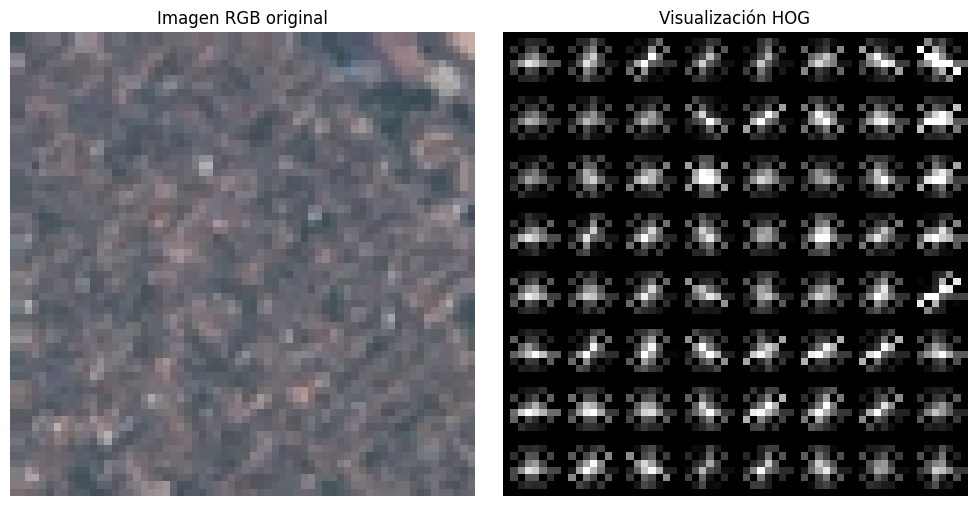

Categoría: Residential
Características RGB: 12288
Características HOG: 1764
Forma del vector HOG: (1764,)


In [15]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 14: Extracción y visualización de HOG
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from skimage.color import rgb2gray
from skimage.feature import hog
from skimage import exposure

# ------------------------------------------------------------
# 1. Recuperar una imagen del conjunto de entrenamiento
# ------------------------------------------------------------

# Reutilizamos el índice seleccionado anteriormente.
# Esta imagen pertenece exclusivamente a entrenamiento.
imagen_pil, etiqueta = dataset[int(indices_train[0])]

# Convertimos la imagen RGB a un array de NumPy.
imagen_rgb = np.asarray(imagen_pil)

# ------------------------------------------------------------
# 2. Convertir la imagen a escala de grises
# ------------------------------------------------------------

# HOG puede calcularse sobre imágenes en escala de grises.
#
# rgb2gray combina los canales RGB para obtener
# una imagen bidimensional de intensidades.
#
# La salida tiene dimensiones (64, 64).
imagen_gris = rgb2gray(imagen_rgb)

print("Forma RGB:", imagen_rgb.shape)
print("Forma escala de grises:", imagen_gris.shape)

# ------------------------------------------------------------
# 3. Extraer características HOG
# ------------------------------------------------------------

# orientations=9:
#   Utilizamos 9 intervalos de orientación.
#
# pixels_per_cell=(8, 8):
#   Cada celda HOG representa una región de 8×8 píxeles.
#
# cells_per_block=(2, 2):
#   Cada bloque agrupa 2×2 celdas para normalizar
#   los histogramas de gradientes.
#
# visualize=True:
#   Devuelve también una imagen que permite observar
#   una representación visual de los gradientes.
#
# feature_vector=True:
#   Devuelve las características como vector 1D.
#
# transform_sqrt=False:
#   Desactivamos la transformación de raíz cuadrada
#   para comenzar con una configuración sencilla.

vector_hog, imagen_hog = hog(
    imagen_gris,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True,
    feature_vector=True,
    transform_sqrt=False
)

# ------------------------------------------------------------
# 4. Mejorar la visualización HOG
# ------------------------------------------------------------

# RescaleIntensity ajusta el contraste de visualización.
#
# No modifica el vector de características que
# utilizaríamos posteriormente para entrenar.
imagen_hog_visual = exposure.rescale_intensity(
    imagen_hog,
    in_range=(0, np.percentile(imagen_hog, 99))
)

# ------------------------------------------------------------
# 5. Comparar la imagen original con HOG
# ------------------------------------------------------------

figura, ejes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(10, 5)
)

# Imagen RGB original.
ejes[0].imshow(imagen_rgb)
ejes[0].set_title("Imagen RGB original")
ejes[0].axis("off")

# Representación visual de HOG.
ejes[1].imshow(
    imagen_hog_visual,
    cmap="gray"
)
ejes[1].set_title("Visualización HOG")
ejes[1].axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Comprobar las dimensiones del descriptor
# ------------------------------------------------------------

print("Categoría:", dataset.classes[etiqueta])

print("Características RGB:", imagen_rgb.size)

print("Características HOG:", len(vector_hog))

print("Forma del vector HOG:", vector_hog.shape)



## 15. Preparación de características HOG

### Objetivo

Extraer características HOG de las mismas imágenes
utilizadas en nuestro experimento anterior.

Conjuntos:
- Entrenamiento: 2.000 imágenes.
- Validación: 1.000 imágenes.
- Prueba: permanece reservada.

### Hipótesis

Una representación basada en patrones locales
de gradientes podría mejorar la generalización
respecto a los píxeles RGB aplanados.

### Decisiones técnicas

1. Conservamos los mismos índices de imágenes.
2. Aplicamos idénticos parámetros HOG a ambos conjuntos.
3. No utilizamos datos de prueba.
4. No entrenamos ningún modelo todavía.

### Limitaciones

La conversión a escala de grises elimina información
de color, que podría ser relevante para distinguir
tipos de vegetación y masas de agua.

Una reducción en el número de características no
garantiza una mejora del rendimiento.


In [16]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 15: Preparación de características HOG
# ============================================================

import time
import numpy as np

from skimage.color import rgb2gray
from skimage.feature import hog

# ------------------------------------------------------------
# 1. Definir una función reutilizable
# ------------------------------------------------------------

def extraer_hog(indice):
    """
    Extrae características HOG de una imagen EuroSAT.

    Parámetros
    ----------
    indice : int
        Posición de la imagen dentro del dataset.

    Devuelve
    --------
    caracteristicas : np.ndarray
        Vector HOG de 1.764 características.

    etiqueta : int
        Categoría numérica de la imagen.
    """

    # Recuperamos la imagen y su etiqueta.
    imagen, etiqueta = dataset[int(indice)]

    # Convertimos PIL a un array RGB.
    imagen_rgb = np.asarray(imagen)

    # Convertimos a escala de grises.
    # Así aplicamos la misma configuración HOG
    # que utilizamos en el paso anterior.
    imagen_gris = rgb2gray(imagen_rgb)

    # Extraemos el descriptor HOG.
    # visualize=False evita calcular una imagen
    # adicional que no necesitamos para entrenar.
    caracteristicas = hog(
        imagen_gris,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=False,
        feature_vector=True,
        transform_sqrt=False
    )

    # Convertimos a float32 para reducir memoria.
    caracteristicas = caracteristicas.astype(np.float32)

    return caracteristicas, etiqueta


# ------------------------------------------------------------
# 2. Función para procesar múltiples imágenes
# ------------------------------------------------------------

def preparar_conjunto_hog(indices_conjunto):
    """
    Convierte una colección de imágenes en una matriz HOG.

    Devuelve
    --------
    X : matriz de características
    y : vector de etiquetas
    """

    vectores = []
    etiquetas_conjunto = []

    for indice in indices_conjunto:

        vector, etiqueta = extraer_hog(indice)

        vectores.append(vector)
        etiquetas_conjunto.append(etiqueta)

    # Cada fila representa una imagen.
    X = np.stack(vectores)

    # Cada elemento representa su clase real.
    y = np.array(etiquetas_conjunto)

    return X, y


# ------------------------------------------------------------
# 3. Procesar entrenamiento y validación
# ------------------------------------------------------------

inicio = time.time()

X_train_hog, y_train_hog = preparar_conjunto_hog(
    indices_muestra
)

X_val_hog, y_val_hog = preparar_conjunto_hog(
    indices_val_muestra
)

tiempo_extraccion = time.time() - inicio


# ------------------------------------------------------------
# 4. Comprobar resultados y correspondencia
# ------------------------------------------------------------

print("Forma X_train_hog:", X_train_hog.shape)
print("Forma y_train_hog:", y_train_hog.shape)

print("Forma X_val_hog:", X_val_hog.shape)
print("Forma y_val_hog:", y_val_hog.shape)

# Confirmamos que las etiquetas corresponden
# exactamente a las de los experimentos anteriores.
assert np.array_equal(y_train_hog, y_train_sample)
assert np.array_equal(y_val_hog, y_val_sample)

# Comprobamos el número de características.
assert X_train_hog.shape[1] == 1764
assert X_val_hog.shape[1] == 1764

# Verificamos que no haya valores NaN o infinitos.
assert np.isfinite(X_train_hog).all()
assert np.isfinite(X_val_hog).all()

print(
    "Tiempo de extracción:",
    round(tiempo_extraccion, 2),
    "segundos"
)

print("Matrices HOG preparadas correctamente.")


Forma X_train_hog: (2000, 1764)
Forma y_train_hog: (2000,)
Forma X_val_hog: (1000, 1764)
Forma y_val_hog: (1000,)
Tiempo de extracción: 10.75 segundos
Matrices HOG preparadas correctamente.



## 16. Comparación de modelos: RGB frente a HOG

### Objetivo

Comprobar si las características HOG permiten mejorar
la clasificación de imágenes EuroSAT respecto a los
valores RGB aplanados.

### Hipótesis

HOG podría ofrecer una mejor generalización al
representar patrones locales de bordes y texturas.

### Diseño experimental

Mantendremos constantes:

- Las 2.000 imágenes de entrenamiento.
- Las 1.000 imágenes de validación.
- El algoritmo SGDClassifier.
- Los parámetros de regularización y optimización.
- La métrica principal: macro-F1.

Cambiaremos:

- La representación de entrada: RGB frente a HOG.

### Limitaciones

Aunque mantengamos alpha=0.001, las características
tienen distinta dimensionalidad y distribución.
Por tanto, este experimento compara dos pipelines
concretos, no demuestra que una representación sea
universalmente superior.

El conjunto de prueba permanece reservado.


In [17]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 16: Entrenamiento y evaluación con HOG
# ============================================================

import time
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------------------
# 1. Crear el pipeline del modelo HOG
# ------------------------------------------------------------

# Pipeline conecta dos operaciones:
#
# StandardScaler:
#   Aprende la media y desviación estándar de cada
#   característica utilizando solo entrenamiento.
#
# SGDClassifier:
#   Aprende a clasificar imágenes mediante un
#   modelo lineal con pérdida logística.
#
# Mantenemos los parámetros del modelo RGB mejorado
# para comparar ambas representaciones.

modelo_hog = Pipeline([
    (
        "escalador",
        StandardScaler()
    ),
    (
        "clasificador",
        SGDClassifier(
            loss="log_loss",
            alpha=0.001,
            max_iter=1000,
            tol=1e-3,
            random_state=42,
            n_jobs=-1
        )
    )
])

# ------------------------------------------------------------
# 2. Entrenar el modelo
# ------------------------------------------------------------

# Medimos únicamente el tiempo de ajuste del pipeline.
# No incluimos la extracción previa de HOG.
inicio_entrenamiento = time.perf_counter()

modelo_hog.fit(
    X_train_hog,
    y_train_hog
)

tiempo_entrenamiento_hog = (
    time.perf_counter() - inicio_entrenamiento
)

# ------------------------------------------------------------
# 3. Obtener predicciones
# ------------------------------------------------------------

# Evaluamos sobre entrenamiento para comprobar
# cuánto se ajusta el modelo a los datos conocidos.
pred_train_hog = modelo_hog.predict(X_train_hog)

# Evaluamos sobre imágenes no utilizadas
# durante el entrenamiento.
pred_val_hog = modelo_hog.predict(X_val_hog)

# ------------------------------------------------------------
# 4. Calcular las métricas
# ------------------------------------------------------------

# Accuracy: proporción de predicciones correctas.
accuracy_train_hog = accuracy_score(
    y_train_hog,
    pred_train_hog
)

accuracy_val_hog = accuracy_score(
    y_val_hog,
    pred_val_hog
)

# Macro-F1: promedio del F1 de todas las clases.
# Cada categoría tiene el mismo peso.
f1_train_hog = f1_score(
    y_train_hog,
    pred_train_hog,
    average="macro",
    zero_division=0
)

f1_val_hog = f1_score(
    y_val_hog,
    pred_val_hog,
    average="macro",
    zero_division=0
)

# ------------------------------------------------------------
# 5. Comparar RGB y HOG
# ------------------------------------------------------------

# Las variables del modelo RGB proceden del paso 14.
# Ambas evaluaciones utilizan las mismas imágenes.
comparativa = pd.DataFrame([
    {
        "Representación": "RGB",
        "Características": X_train_sample.shape[1],
        "Accuracy train": accuracy_train_mejorado,
        "Accuracy val": accuracy_val_mejorado,
        "Macro-F1 train": f1_train_mejorado,
        "Macro-F1 val": f1_val_mejorado
    },
    {
        "Representación": "HOG",
        "Características": X_train_hog.shape[1],
        "Accuracy train": accuracy_train_hog,
        "Accuracy val": accuracy_val_hog,
        "Macro-F1 train": f1_train_hog,
        "Macro-F1 val": f1_val_hog
    }
])

# Formateamos la tabla para mostrar cuatro decimales.
display(comparativa.round(4))

# ------------------------------------------------------------
# 6. Mostrar tiempo y diferencia de rendimiento
# ------------------------------------------------------------

print(
    "Tiempo de entrenamiento HOG:",
    round(tiempo_entrenamiento_hog, 2),
    "segundos"
)

# Diferencia positiva: HOG supera a RGB.
# Diferencia negativa: HOG rinde peor que RGB.
diferencia_f1 = f1_val_hog - f1_val_mejorado

print(
    "Diferencia de Macro-F1 (HOG - RGB):",
    round(diferencia_f1, 4)
)

print("Comparación completada.")


,Representación,Características,Accuracy train,Accuracy val,Macro-F1 train,Macro-F1 val
0,RGB,12288,0.757,0.410,0.7559,0.3921
1,HOG,1764,0.941,0.473,0.9386,0.4625


Tiempo de entrenamiento HOG: 20.73 segundos
Diferencia de Macro-F1 (HOG - RGB): 0.0703
Comparación completada.



## 17. Optimización de la regularización del modelo HOG

### Objetivo

Investigar si una regularización más intensa puede
mejorar la generalización del clasificador HOG.

### Resultados del modelo HOG actual

- Alpha: 0.001
- Accuracy entrenamiento: 94,1 %
- Accuracy validación: 47,3 %
- Macro-F1 validación: 0,4625
- Brecha accuracy: 46,8 puntos porcentuales

### Hipótesis

El modelo podría estar ajustándose demasiado a las
particularidades de las 2.000 imágenes de entrenamiento.

Una regularización mayor podría reducir el sobreajuste.

### Conceptos

**Alpha:** parámetro que controla la intensidad
de la regularización en SGDClassifier.

**Sobreajuste:** el modelo obtiene resultados mucho
mejores en entrenamiento que en datos no vistos.

**Selección de hiperparámetros:** comparación de
configuraciones utilizando datos de validación.

### Diseño experimental

Mantendremos constantes:

- Las imágenes de entrenamiento y validación.
- Las características HOG.
- El escalado StandardScaler.
- El algoritmo SGDClassifier.
- La semilla aleatoria.

Modificaremos exclusivamente el valor de alpha.

El conjunto de prueba permanecerá reservado.


In [18]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 17: Regularización del clasificador HOG
# ============================================================

import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------------------
# 1. Definir los valores de regularización
# ------------------------------------------------------------

# Ya hemos probado alpha=0.001.
# Ahora evaluaremos valores mayores.
#
# Un alpha mayor implica una penalización más intensa
# sobre los coeficientes del clasificador.
#
# No sabemos de antemano qué valor funcionará mejor.
valores_alpha_hog = [
    0.001,
    0.01,
    0.1,
    1.0
]

# Guardaremos las métricas de cada experimento.
resultados_hog = []

# ------------------------------------------------------------
# 2. Entrenar y evaluar cada configuración
# ------------------------------------------------------------

for alpha in valores_alpha_hog:

    # Construimos un pipeline nuevo para cada alpha.
    # Así evitamos reutilizar parámetros aprendidos.
    modelo = Pipeline([
        (
            "escalador",
            StandardScaler()
        ),
        (
            "clasificador",
            SGDClassifier(
                loss="log_loss",
                alpha=alpha,
                max_iter=1000,
                tol=1e-3,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    # Entrenamos solo con la muestra de entrenamiento.
    modelo.fit(X_train_hog, y_train_hog)

    # Predecimos sobre train y validation.
    pred_train = modelo.predict(X_train_hog)
    pred_val = modelo.predict(X_val_hog)

    # Calculamos accuracy.
    acc_train = accuracy_score(y_train_hog, pred_train)
    acc_val = accuracy_score(y_val_hog, pred_val)

    # Calculamos macro-F1 para las diez categorías.
    f1_train = f1_score(
        y_train_hog,
        pred_train,
        average="macro",
        zero_division=0
    )

    f1_val = f1_score(
        y_val_hog,
        pred_val,
        average="macro",
        zero_division=0
    )

    # Guardamos todas las métricas relevantes.
    resultados_hog.append({
        "alpha": alpha,
        "accuracy_train": acc_train,
        "accuracy_val": acc_val,
        "macro_f1_train": f1_train,
        "macro_f1_val": f1_val,
        "brecha_accuracy": acc_train - acc_val
    })

    print(
        f"alpha={alpha} | "
        f"accuracy_val={acc_val:.4f} | "
        f"macro_f1_val={f1_val:.4f}"
    )

# ------------------------------------------------------------
# 3. Construir la tabla comparativa
# ------------------------------------------------------------

tabla_hog = pd.DataFrame(resultados_hog)

# Seleccionamos la configuración con mejor macro-F1
# entre los valores probados.
tabla_hog = tabla_hog.sort_values(
    by="macro_f1_val",
    ascending=False
)

display(tabla_hog.round(4))

# ------------------------------------------------------------
# 4. Identificar la mejor configuración
# ------------------------------------------------------------

mejor_hog = tabla_hog.iloc[0]

print("Mejor alpha HOG:", mejor_hog["alpha"])

print(
    "Mejor macro-F1 validación:",
    round(mejor_hog["macro_f1_val"], 4)
)


alpha=0.001 | accuracy_val=0.4730 | macro_f1_val=0.4625
alpha=0.01 | accuracy_val=0.4900 | macro_f1_val=0.4732
alpha=0.1 | accuracy_val=0.5030 | macro_f1_val=0.4710
alpha=1.0 | accuracy_val=0.4750 | macro_f1_val=0.4024


,alpha,accuracy_train,accuracy_val,macro_f1_train,macro_f1_val,brecha_accuracy
1,0.010,0.8980,0.490,0.8930,0.4732,0.4080
2,0.100,0.8375,0.503,0.8256,0.4710,0.3345
0,0.001,0.9410,0.473,0.9386,0.4625,0.4680
3,1.000,0.6580,0.475,0.6182,0.4024,0.1830


Mejor alpha HOG: 0.01
Mejor macro-F1 validación: 0.4732



## 18. Registro y comparación de experimentos

### Objetivo

Consolidar los resultados de los modelos evaluados
durante el desarrollo del proyecto.

### Modelos analizados

1. Baseline RGB + SGDClassifier.
2. RGB + StandardScaler + SGDClassifier.
3. HOG + StandardScaler + SGDClassifier.
4. HOG con diferentes valores de regularización.

### Métrica principal

Macro-F1 de validación.

Esta métrica asigna la misma importancia a las
diez categorías y permite comparar el rendimiento
equilibrado entre clases.

### Interpretación

La selección de modelos se realiza sobre un conjunto
de validación de 1.000 imágenes.

Estas comparaciones son exploratorias: la reutilización
de la validación para tomar decisiones introduce cierto
riesgo de sobreajuste durante la selección.

El conjunto de prueba continúa reservado.

### Objetivo profesional

Mantener un registro reproducible de las decisiones
experimentales para documentarlas en GitHub.


In [19]:

# ============================================================
# PROYECTO: GeoAI Land Cover Classifier
# ETAPA 18: Registro de experimentos
# ============================================================

import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. Definir el historial de experimentos
# ------------------------------------------------------------

# Estos resultados proceden de las ejecuciones
# anteriores de nuestro notebook.
#
# Registramos solo configuraciones realmente probadas.
# No utilizamos resultados hipotéticos.

experimentos = [
    {
        "modelo": "RGB + SGD baseline",
        "representacion": "RGB",
        "alpha": 0.0001,
        "escalado": False,
        "accuracy_val": 0.281,
        "macro_f1_val": 0.2615
    },
    {
        "modelo": "RGB + SGD optimizado",
        "representacion": "RGB",
        "alpha": 0.001,
        "escalado": True,
        "accuracy_val": 0.410,
        "macro_f1_val": 0.3921
    },
    {
        "modelo": "HOG + SGD",
        "representacion": "HOG",
        "alpha": 0.001,
        "escalado": True,
        "accuracy_val": 0.473,
        "macro_f1_val": 0.4625
    },
    {
        "modelo": "HOG + SGD",
        "representacion": "HOG",
        "alpha": 0.01,
        "escalado": True,
        "accuracy_val": 0.490,
        "macro_f1_val": 0.4732
    },
    {
        "modelo": "HOG + SGD",
        "representacion": "HOG",
        "alpha": 0.1,
        "escalado": True,
        "accuracy_val": 0.503,
        "macro_f1_val": 0.4710
    },
    {
        "modelo": "HOG + SGD",
        "representacion": "HOG",
        "alpha": 1.0,
        "escalado": True,
        "accuracy_val": 0.475,
        "macro_f1_val": 0.4024
    }
]

# ------------------------------------------------------------
# 2. Crear tabla y ordenar por macro-F1
# ------------------------------------------------------------

registro_experimentos = pd.DataFrame(experimentos)

registro_ordenado = registro_experimentos.sort_values(
    by="macro_f1_val",
    ascending=False
)

display(registro_ordenado)

# ------------------------------------------------------------
# 3. Guardar resultados en CSV
# ------------------------------------------------------------

# Creamos una carpeta para guardar resultados.
# exist_ok=True evita errores si ya existe.
carpeta_resultados = Path("results")
carpeta_resultados.mkdir(exist_ok=True)

# Guardamos los resultados sin la columna de índice.
ruta_csv = carpeta_resultados / "experiments.csv"

registro_experimentos.to_csv(
    ruta_csv,
    index=False
)

print("Archivo CSV generado:", ruta_csv)

# ------------------------------------------------------------
# 4. Comprobar que el archivo existe
# ------------------------------------------------------------

assert ruta_csv.exists()

print("Registro guardado correctamente.")


,modelo,representacion,alpha,escalado,accuracy_val,macro_f1_val
3,HOG + SGD,HOG,0.0100,True,0.490,0.4732
4,HOG + SGD,HOG,0.1000,True,0.503,0.4710
2,HOG + SGD,HOG,0.0010,True,0.473,0.4625
5,HOG + SGD,HOG,1.0000,True,0.475,0.4024
1,RGB + SGD optimizado,RGB,0.0010,True,0.410,0.3921
0,RGB + SGD baseline,RGB,0.0001,False,0.281,0.2615


Archivo CSV generado: results/experiments.csv
Registro guardado correctamente.
